## Packages

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google import genai
from google.genai.types import EmbedContentConfig

In [3]:
from embedding import embedding

## Global Variables

In [4]:
from dotenv import load_dotenv
load_dotenv()

SNAPSHOT_PATH = os.environ["SNAPSHOT_PATH"]

In [5]:
from common.configuration import EMBEDDING_MODEL, EMBEDDING_TASK_TYPE, DIMENSION, QUERY_TASK_TYPE

## Alignment

We examine whether the embedded vectors stored in ```vectors.npy``` are in the same order as embedded text in ```chunks.jsonl```. To check this, we embed those embedded text with the same embedding configuration once again, then compare the similarities of embedded vectors with those in ```vectors.npy```.

During snapshots exporting process, both ```chunks.jsonl``` and ```vectors.npy``` are generated in the descending order of post timestamps. This should ensure they are align with each other.

In [6]:
# chunks.jsonl
with open(f"{SNAPSHOT_PATH}/chunks.jsonl", "r") as f:
    chunks = [json.loads(line) for line in f]
    
# vectors.npy
vectors = np.load(f"{SNAPSHOT_PATH}/vectors.npy")

In [42]:
# embedding
embed_text = [chunk["text"] for chunk in chunks]
embeddings = embedding(embed_text)

Text(0.5, 1.0, 'Inner Product Diff. From 1.\nNewly Embedded Vectors vs. Vectors.npy')

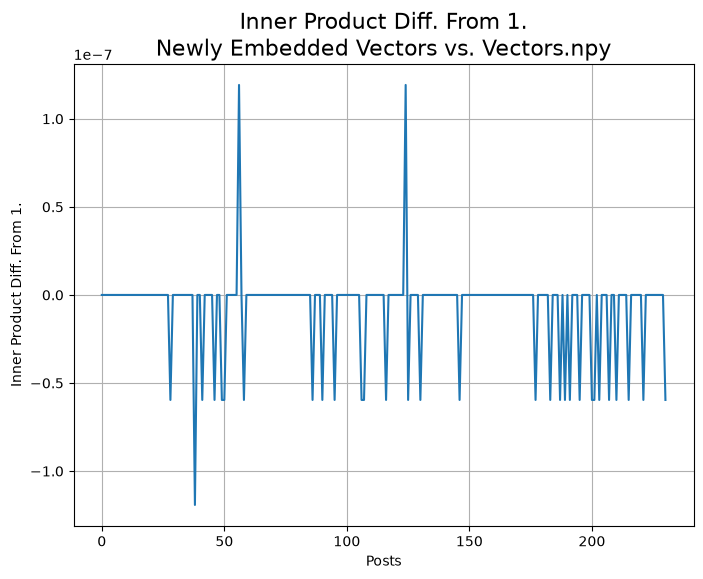

In [66]:
# similarity comparison
embeddings   = np.asarray(embeddings, dtype = np.float32)
similarities = np.sum(embeddings * vectors, axis = (1,))

plt.figure(figsize = (8, 6))
plt.plot(similarities - 1.)
plt.grid()
plt.xlabel("Posts")
plt.ylabel("Inner Product Diff. From 1.")
plt.title("Inner Product Diff. From 1.\nNewly Embedded Vectors vs. Vectors.npy", fontsize = 16)

## Query

In this part of examination, we want to check whether the query text can be linked to correct posts in the corpus very quick.

In [102]:
query_list = [
    "冰晶為什麼會比水滴更容易成長？",
    "溫室氣體怎麼影響地球的能量平衡？",
    "資料同化在數值天氣預報中扮演什麼角色？",
    "系集預報要怎麼兼顧發散程度和預報準確度？",
    "土壤濕度為什麼會影響到一個月後的天氣預報？"
]

In [103]:
with genai.Client() as client:
    response = client.models.embed_content(
        model    = EMBEDDING_MODEL,
        contents = query_list,
        config   = EmbedContentConfig(
            task_type = QUERY_TASK_TYPE,
            output_dimensionality = DIMENSION
        )
    )
    
    query_embeddings = []
    for emb in response.embeddings:
        emb  = np.asarray(emb.values)
        emb /= np.sqrt(np.sum(np.square(emb)))
        query_embeddings.append(emb)

In [104]:
ids = [chunk["id"] for chunk in chunks]

In [105]:
num_search = 5

for _, q in enumerate(query_list):
    similarities = np.dot(vectors, query_embeddings[_])
    tuple_ids_similarities = [(i, s) for i, s in zip(ids, similarities)]
    retrieved = sorted(tuple_ids_similarities, key = lambda t: t[1], reverse = True)[:num_search]
    
    print("問題：", q + "\n")
    for r in retrieved:
        print(chunks[np.squeeze(np.where(np.asarray([chunk["id"] == r[0] for chunk in chunks])))]["text"] + "\n")
        print("---")
    print("===========================")

問題： 冰晶為什麼會比水滴更容易成長？

大氣中的冰晶成長過程五花八門。

因為水分子的結構，在冰晶形成的時候會以六角形的方式排列。但即便都是六角形，其成長的偏好方向會隨著溫度與水氣過飽和度而改變。

如下圖一，在 0 到 -5 度之間，冰晶以片狀成長為主，但溫度降低到 -5 到 -10 度時便會變成柱狀成長，再接著降溫時其偏好又會改變。

當冰晶形成並開始向地面下落的時候，一路上會經歷各種不同的溫度與過飽和度的變化，因此會經歷數種成長的過程。正如下圖二所示，同一塊冰晶上柱狀與片狀成長的結構會同時出現。

由於每一塊冰晶在下落時經歷的路程都不一樣，也因此不會有任何兩片雪花的形狀會一模一樣。

圖片來源：Libbrecht 2008、Roland Stull

References

Libbrecht, Kenneth. (2008). Crystal Growth in the Presence of Surface Melting and Impurities: An Explanation of Snow Crystal Growth Morphologies. 

https://geo.libretexts.org/Bookshelves/Meteorology_and_Climate_Science/Practical_Meteorology_(Stull)/07%3A_Precipitation_Processes/7.05%3A_Ice_Growth_by_Diffusion

---
韋格納 – 白吉龍 – 芬德森過程（Wegener–Bergeron–Findeisen process, WBF process）是冷雲過程中的一個重要物理過程。

當雨水的形成牽涉到冰晶相關的過程，這就被稱為冷雲過程，而冷雲過程當中 WBF process 是其中一個使冰晶成長的重要效應。因為冰晶表面的飽和蒸氣壓比液態水表面的飽和蒸氣壓來得小，因此當環境中同時有大量的冰晶和水滴時，水滴會傾向蒸發，同時水分子會傾向凝華於冰晶表面上。

當冰晶成長得足夠大，便會掉落出 WBF process 發生的區域，後續會繼續維持冰晶的形式到落地（雪）或是融化變成液態水（雨）則取決於環境的溫度高低。

圖片來源：Nicosia 2018, Tarbuck and Lutgens 